<a href="https://colab.research.google.com/github/teoespero/BixbySight/blob/main/BixbySight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **What Can You See From Bixby Bridge?**

**30 Day Map Challenge | Google Colab | Big Sur, California**

Imagine you’re standing at the pullout north of Bixby Bridge. You can see parts of the coast, but nearby ridges may hide sections of the canyon. In this lab, you’ll use elevation data to map which parts of the landscape are visible from that viewpoint.

A viewshed is the area that can be seen from a particular location. For this lab, we’ll model a person whose eyes are 1.7 meters above the ground.

### **1. Install and import the libraries**

In [1]:
%pip -q install rasterio pyproj

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer

print("Setup complete. The mapping libraries loaded successfully.")

Setup complete. The mapping libraries loaded successfully.


### **2. Locate the observer and define the study area**

Use the mapped viewpoint at 36.37244° N, 121.90268° W as the observer location. This gives everyone in the lab the same starting point at the pullout north of Bixby Bridge. Monterey County, California, USA

For the first run, use a 6 km × 6 km study area centered on the viewpoint. The square sets the area we’ll request elevation data for. We’ll decide which terrain is visible in a later cell.

In [2]:
# The viewpoint is stored in latitude and longitude.
observer_lat = 36.37244
observer_lon = -121.90268
observer_height_m = 1.7  # Eye height above the ground

# Convert to UTM Zone 10N so we can work in meters.
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32610", always_xy=True)
observer_x, observer_y = to_utm.transform(observer_lon, observer_lat)

# Extend the study area 3,000 meters in each direction from the observer.
half_width_m = 3_000
west = observer_x - half_width_m
south = observer_y - half_width_m
east = observer_x + half_width_m
north = observer_y + half_width_m

study_bounds_utm = (west, south, east, north)

print(f"Observer location: {observer_lat:.5f}, {observer_lon:.5f}")
print(f"Observer height: {observer_height_m:.1f} m above ground")
print(f"Study area: {(east - west) / 1000:.1f} km × {(north - south) / 1000:.1f} km")

Observer location: 36.37244, -121.90268
Observer height: 1.7 m above ground
Study area: 6.0 km × 6.0 km


### **3. Download and inspect the elevation data**

A digital elevation model (DEM) is a grid in which each cell stores an elevation. In this task, you’ll download a DEM from the USGS 3D Elevation Program (3DEP), plot the terrain, and check the ground elevation at the observer’s location. elevation.nationalmap.gov

We’ll request a 600 × 600 grid for the 6 km × 6 km study area. That gives us 10-meter output cells. The output cell size describes the grid we request, while the source elevation data can vary in resolution.

Raster size: 600 columns × 600 rows
Cell size: 10.0 m × 10.0 m
Ground elevation at the observer: 82.3 m
Observer eye elevation: 84.0 m


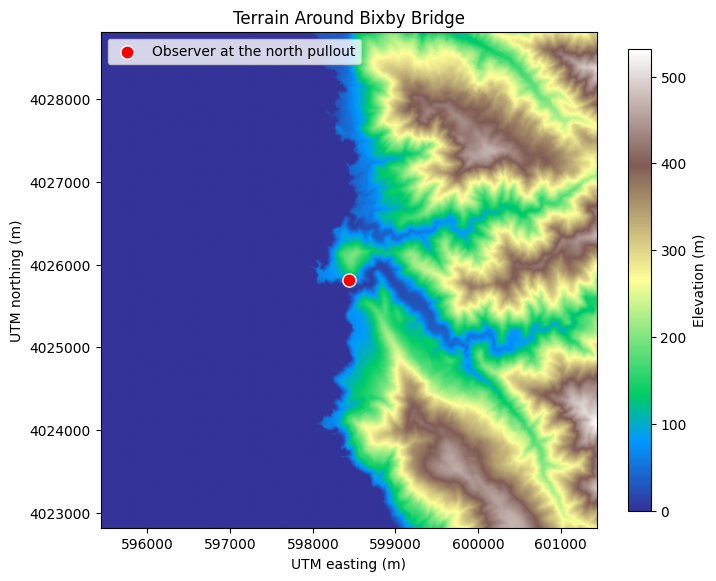

In [3]:
from pathlib import Path

import requests
from rasterio.plot import plotting_extent

# 1. Request a GeoTIFF for the study area defined in Cell 2.
dem_url = (
    "https://elevation.nationalmap.gov/arcgis/rest/services/"
    "3DEPElevation/ImageServer/exportImage"
)

params = {
    "bbox": ",".join(str(value) for value in study_bounds_utm),
    "bboxSR": "32610",
    "imageSR": "32610",
    "size": "600,600",
    "format": "tiff",
    "pixelType": "F32",
    "interpolation": "RSP_BilinearInterpolation",
    "f": "image",
}

response = requests.get(dem_url, params=params, timeout=120)
response.raise_for_status()

# Open the response as a raster before saving it as a GeoTIFF.
with rasterio.MemoryFile(response.content) as memory_file:
    with memory_file.open() as src:
        if src.crs is None or src.crs.to_epsg() != 32610:
            raise ValueError(f"Expected UTM Zone 10N. Received {src.crs}.")

        # 2. Keep missing elevation cells masked so they stay blank on the map.
        dem = np.ma.masked_invalid(src.read(1, masked=True))
        dem_transform = src.transform
        cell_width_m, cell_height_m = src.res
        dem_extent = plotting_extent(src)
        observer_row, observer_col = src.index(observer_x, observer_y)

# 3. Check that the observer falls on a cell with valid elevation.
rows, cols = dem.shape
if not (0 <= observer_row < rows and 0 <= observer_col < cols):
    raise ValueError("The observer falls outside the downloaded DEM.")

ground_elevation_m = dem[observer_row, observer_col]
if np.ma.is_masked(ground_elevation_m):
    raise ValueError("The observer's cell has no elevation data.")

observer_elevation_m = float(ground_elevation_m) + observer_height_m

dem_path = Path("bixby_bridge_3dep_dem.tif")
dem_path.write_bytes(response.content)

print(f"Raster size: {cols} columns × {rows} rows")
print(f"Cell size: {cell_width_m:.1f} m × {cell_height_m:.1f} m")
print(f"Ground elevation at the observer: {ground_elevation_m:.1f} m")
print(f"Observer eye elevation: {observer_elevation_m:.1f} m")

# 4. Plot the elevation grid and mark the observer.
fig, ax = plt.subplots(figsize=(8, 8))

terrain = ax.imshow(dem, extent=dem_extent, origin="upper", cmap="terrain")
ax.scatter(
    observer_x, observer_y,
    color="red", edgecolor="white", s=90,
    label="Observer at the north pullout", zorder=3,
)

ax.set(
    title="Terrain Around Bixby Bridge",
    xlabel="UTM easting (m)",
    ylabel="UTM northing (m)",
    aspect="equal",
)
ax.ticklabel_format(style="plain", useOffset=False)
ax.legend(loc="upper left")
fig.colorbar(terrain, ax=ax, label="Elevation (m)", shrink=0.75)

plt.show()

### **4. Calculate the viewshed**

From the north pullout, which slopes can you see, and which are hidden behind a ridge? You’ll use GDAL to calculate visibility from 1.7 meters above the ground. The result assigns each elevation cell a value of 1 for visible or 0 for hidden.

Visible cells: 61,985
Hidden cells: 298,015


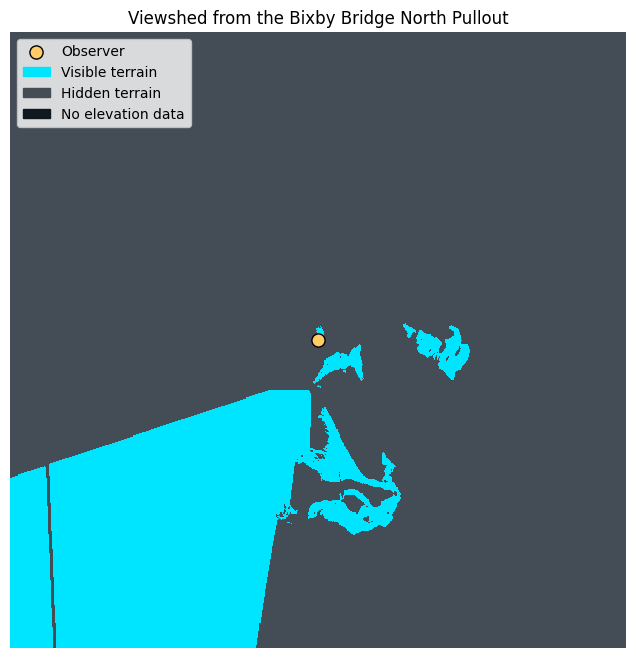

In [4]:
import shutil
import subprocess

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# 1. Install the GDAL command-line tool if Colab does not have it yet.
if shutil.which("gdal_viewshed") is None:
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "gdal-bin"], check=True)

# 2. Calculate visibility across the full DEM from Cell 3.
viewshed_path = Path("bixby_bridge_viewshed.tif")

subprocess.run(
    [
        "gdal_viewshed",
        "-ox", str(observer_x),         # Observer easting
        "-oy", str(observer_y),         # Observer northing
        "-oz", str(observer_height_m),  # Eye height above ground
        "-tz", "0",                     # Check visibility at ground level
        "-vv", "1",                     # Visible
        "-iv", "0",                     # Hidden
        "-a_nodata", "255",
        str(dem_path),
        str(viewshed_path),
    ],
    check=True,
)

# 3. Mask missing elevation cells and count the classified cells.
with rasterio.open(viewshed_path) as src:
    visibility = src.read(1, masked=True)

visibility = np.ma.masked_where(np.ma.getmaskarray(dem), visibility)
classified = visibility.compressed()
visible_count = np.count_nonzero(classified == 1)
hidden_count = np.count_nonzero(classified == 0)

print(f"Visible cells: {visible_count:,}")
print(f"Hidden cells: {hidden_count:,}")

# 4. Preview the result before designing the poster.
colors = ListedColormap(["#444C56", "#00E5FF"])
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_facecolor("#101820")

ax.imshow(
    visibility,
    extent=dem_extent,
    origin="upper",
    cmap=colors,
    vmin=0,
    vmax=1,
    interpolation="nearest",
)

observer_marker = ax.scatter(
    observer_x, observer_y,
    color="#FFCC66", edgecolor="black", s=90,
    label="Observer", zorder=3,
)

ax.legend(handles=[
    observer_marker,
    Patch(color="#00E5FF", label="Visible terrain"),
    Patch(color="#444C56", label="Hidden terrain"),
    Patch(color="#101820", label="No elevation data"),
], loc="upper left")

ax.set(title="Viewshed from the Bixby Bridge North Pullout", aspect="equal")
ax.set_axis_off()
plt.show()

### **5. Design the final viewshed poster**

Use the viewshed from Cell 4 to make a poster for the #30DayMapChallenge. Draw the terrain as dark shaded relief, highlight visible ground in cyan, and mark the north pullout in gold. Keep the cyan layer translucent so readers can still see the shape of the slopes underneath.

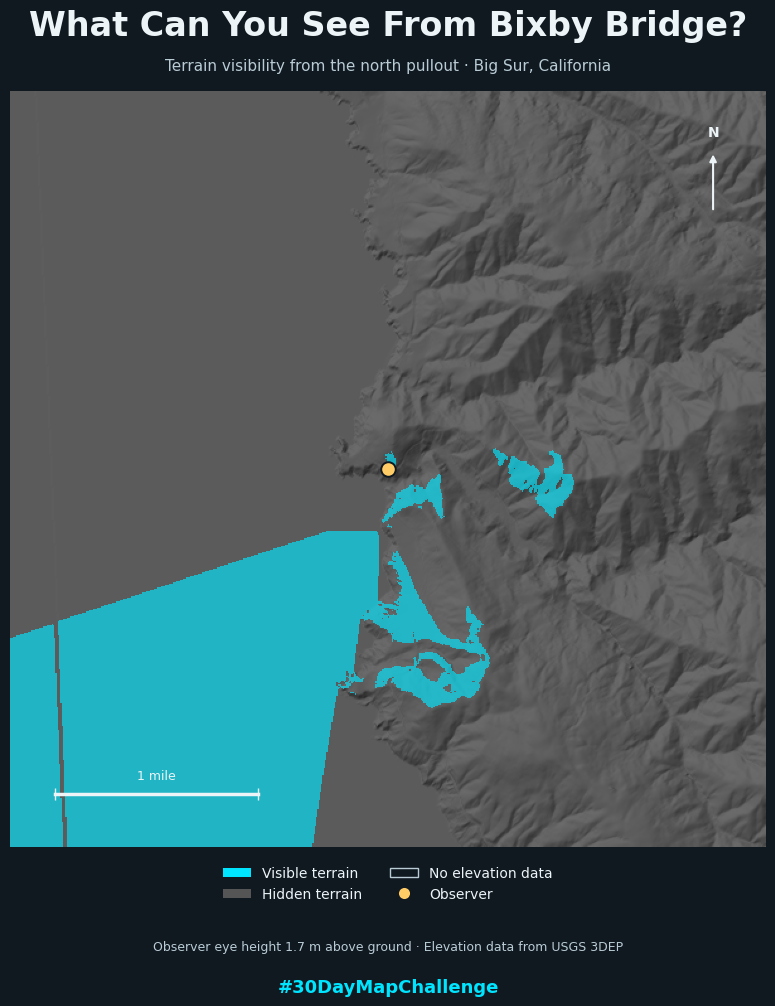

Poster saved as bixby_bridge_viewshed_poster.png


In [5]:
from matplotlib.colors import LightSource
from matplotlib.lines import Line2D

# 1. Make shaded relief from the elevation grid.
background = "#101820"
cyan = "#00E5FF"
gold = "#FFCC66"
text_color = "#ECF4F7"

missing_elevation = np.ma.getmaskarray(dem)

light = LightSource(azdeg=315, altdeg=45)
hillshade = light.hillshade(
    dem.astype(float).filled(np.nan),
    dx=cell_width_m,
    dy=cell_height_m,
)

# Use neutral shading next to gaps and leave missing cells transparent.
hillshade = np.nan_to_num(hillshade, nan=0.5)
gray = 0.14 + 0.28 * hillshade
terrain_rgba = np.stack(
    [gray, gray, gray, (~missing_elevation).astype(float)],
    axis=-1,
)

# 2. Set up the poster and draw the terrain.
fig = plt.figure(figsize=(9, 10.5), facecolor=background)
ax = fig.add_axes([0.08, 0.19, 0.84, 0.72], facecolor=background)

fig.text(
    0.5, 0.963, "What Can You See From Bixby Bridge?",
    ha="center", color=text_color, fontsize=24, fontweight="bold",
)
fig.text(
    0.5, 0.930, "Terrain visibility from the north pullout · Big Sur, California",
    ha="center", color="#B9CCD5", fontsize=11,
)

ax.imshow(terrain_rgba, extent=dem_extent, origin="upper")

# 3. Overlay visible terrain and mark the observer.
visible_overlay = np.ma.masked_where(
    visibility.filled(255) != 1,
    np.ones(dem.shape),
)

ax.imshow(
    visible_overlay,
    extent=dem_extent,
    origin="upper",
    cmap=ListedColormap([cyan]),
    vmin=0,
    vmax=1,
    alpha=0.65,
    interpolation="nearest",
)

ax.scatter(
    observer_x, observer_y,
    s=110, color=gold, edgecolor=background, linewidth=1.4, zorder=5,
)

# 4. Add a grid-north arrow and a one-mile scale bar.
xmin, xmax, ymin, ymax = dem_extent
map_width = xmax - xmin
map_height = ymax - ymin

ax.annotate(
    "",
    xy=(0.93, 0.92), xytext=(0.93, 0.84),
    xycoords="axes fraction",
    arrowprops=dict(arrowstyle="-|>", color=text_color, lw=1.5),
)
ax.text(
    0.93, 0.94, "N", transform=ax.transAxes,
    ha="center", color=text_color, fontweight="bold",
)

scale_x = xmin + 0.06 * map_width
scale_y = ymin + 0.07 * map_height
mile_m = 1609.344

ax.plot(
    [scale_x, scale_x + mile_m], [scale_y, scale_y],
    color=text_color, linewidth=2.5, marker="|", markersize=9,
)
ax.text(
    scale_x + mile_m / 2, scale_y + 0.02 * map_height, "1 mile",
    ha="center", color=text_color, fontsize=9,
)

ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect="equal")
ax.set_axis_off()

# 5. Add the legend and export the poster.
legend_items = [
    Patch(facecolor=cyan, label="Visible terrain"),
    Patch(facecolor="#555555", label="Hidden terrain"),
    Patch(facecolor=background, edgecolor="#B9CCD5", label="No elevation data"),
    Line2D(
        [], [], marker="o", linestyle="none",
        markerfacecolor=gold, markeredgecolor=background,
        markersize=9, label="Observer",
    ),
]

fig.legend(
    handles=legend_items,
    loc="center",
    bbox_to_anchor=(0.5, 0.155),
    ncol=2,
    frameon=False,
    labelcolor=text_color,
)

fig.text(
    0.5, 0.092,
    "Observer eye height 1.7 m above ground · Elevation data from USGS 3DEP",
    ha="center", color="#B9CCD5", fontsize=9,
)
fig.text(
    0.5, 0.052, "#30DayMapChallenge",
    ha="center", color=cyan, fontsize=13, fontweight="bold",
)

poster_path = Path("bixby_bridge_viewshed_poster.png")
fig.savefig(poster_path, dpi=300, facecolor=fig.get_facecolor())
plt.show()

print(f"Poster saved as {poster_path.name}")

### **6. Measure and explain what’s visible**

Your poster shows where the terrain is visible. Now calculate how much of the classified study area is visible from the north pullout. Use the result to write your final interpretation.

In [8]:
# Calculate the area represented by each raster cell.
cell_area_m2 = cell_width_m * cell_height_m

# Convert the cell counts to square kilometers.
visible_area_km2 = visible_count * cell_area_m2 / 1_000_000
hidden_area_km2 = hidden_count * cell_area_m2 / 1_000_000

# Calculate the percentage using cells classified as visible or hidden.
classified_count = visible_count + hidden_count
if classified_count == 0:
    raise ValueError("No cells were classified. Check the output from Cell 4.")

visible_pct = 100 * visible_count / classified_count
excluded_count = dem.size - classified_count

print(f"Visible area: {visible_area_km2:.2f} km²")
print(f"Hidden area: {hidden_area_km2:.2f} km²")
print(f"Share of classified area that is visible: {visible_pct:.1f}%")
print(f"Cells excluded from the calculation: {excluded_count:,}")

Visible area: 6.20 km²
Hidden area: 29.80 km²
Share of classified area that is visible: 17.2%
Cells excluded from the calculation: 0


### **7. Write your results and interpretation**

Add a text cell below Cell 6. Paste the results and interpretation below, then complete the last paragraph using what you see on your poster.

In [9]:
from IPython.display import Markdown, display

# Replace each prompt with what you observed on your maps.
visible_feature = "[describe a cyan area relative to the gold marker]"
hidden_feature = "[describe a gray area relative to the gold marker]"
blocking_terrain = "[identify the ridge or slope between the observer and the hidden area]"
prediction_result = "[explain whether the result matched your prediction from Task 3]"

classified_area_km2 = visible_area_km2 + hidden_area_km2

display(Markdown(f"""
## Viewshed Results — Bixby Bridge

| Result | Value |
|---|---:|
| Visible area | {visible_area_km2:.2f} km² |
| Hidden area | {hidden_area_km2:.2f} km² |
| Share of classified area that is visible | {visible_pct:.1f}% |
| Cells excluded from the calculation | {excluded_count:,} |

From the north pullout, the model estimates that **{visible_area_km2:.2f} km²**
of the **{classified_area_km2:.2f} km²** classified study area is visible
at an eye height of **{observer_height_m:.1f} meters**.

### Map interpretation

**Visible area:** {visible_feature}

**Hidden area:** {hidden_feature}

**What appears to block the view:** {blocking_terrain}

**How this compares with my prediction:** {prediction_result}
"""))


## Viewshed Results — Bixby Bridge

| Result | Value |
|---|---:|
| Visible area | 6.20 km² |
| Hidden area | 29.80 km² |
| Share of classified area that is visible | 17.2% |
| Cells excluded from the calculation | 0 |

From the north pullout, the model estimates that **6.20 km²**
of the **36.00 km²** classified study area is visible
at an eye height of **1.7 meters**.

### Map interpretation

**Visible area:** [describe a cyan area relative to the gold marker]

**Hidden area:** [describe a gray area relative to the gold marker]

**What appears to block the view:** [identify the ridge or slope between the observer and the hidden area]

**How this compares with my prediction:** [explain whether the result matched your prediction from Task 3]


### **8. Create and export the cyberpunk poster**

Loaded 243 shoreline segments from California DWR.


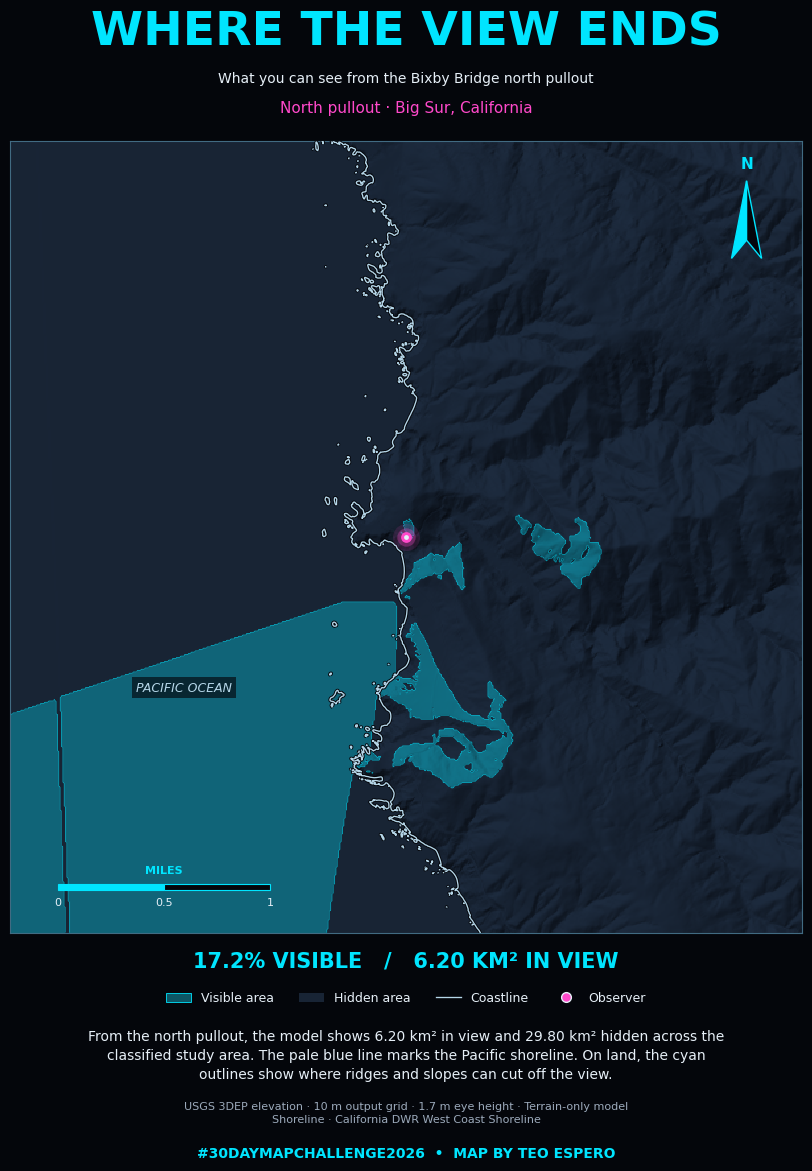

Saved bixby_bridge_neon_sightlines.png


In [21]:
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import requests
from matplotlib.collections import LineCollection
from matplotlib.colors import LightSource, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon, Rectangle

# 1. Set the colors and prepare the shaded terrain.
background = "#04060B"
no_data_color = "#06080F"
cyan = "#00E5FF"
magenta = "#FF49CA"
white = "#E6EFF7"
muted = "#9CAABB"
study_border = "#416B82"
coastline_color = "#B5D6E8"

xmin, xmax, ymin, ymax = dem_extent
map_width = xmax - xmin
map_height = ymax - ymin

elevation = dem.astype(float).filled(np.nan)
hillshade = LightSource(azdeg=315, altdeg=45).hillshade(
    elevation,
    dx=cell_width_m,
    dy=cell_height_m,
)
shade = np.clip(np.nan_to_num(hillshade, nan=0.45), 0, 1)[..., None]

classes = visibility.filled(255)
visible = classes == 1
hidden = classes == 0
classified = visible | hidden

# Blend cyan into the shaded terrain at 10–40% opacity.
terrain_base = np.array([0.025, 0.040, 0.065])
terrain_highlight = np.array([0.09, 0.13, 0.18])
hidden_rgb = terrain_base + shade * terrain_highlight

cyan_rgb = np.array(to_rgb(cyan))
cyan_opacity = 0.10 + 0.30 * shade
visible_rgb = hidden_rgb * (1 - cyan_opacity) + cyan_rgb * cyan_opacity

map_rgb = np.where(visible[..., None], visible_rgb, hidden_rgb)
map_rgb = np.where(classified[..., None], map_rgb, to_rgb(no_data_color))

# 2. Request shoreline lines in the DEM's UTM Zone 10N coordinates.
shoreline_url = (
    "https://gis.water.ca.gov/arcgis/rest/services/"
    "Boundaries/i03_WestCoastShoreline/FeatureServer/0/query"
)

shoreline_params = {
    "f": "json",
    "where": "1=1",
    "geometry": f"{xmin},{ymin},{xmax},{ymax}",
    "geometryType": "esriGeometryEnvelope",
    "inSR": 32610,
    "outSR": 32610,
    "spatialRel": "esriSpatialRelIntersects",
    "returnGeometry": "true",
}

try:
    response = requests.get(
        shoreline_url, params=shoreline_params, timeout=(10, 45)
    )
    response.raise_for_status()
    shoreline_data = response.json()
except (requests.RequestException, ValueError) as error:
    raise RuntimeError(f"Could not download the California DWR shoreline: {error}") from error

# ArcGIS may report a query error inside a successful HTTP response.
if "error" in shoreline_data:
    error = shoreline_data["error"]
    message = error.get("message", "Unknown ArcGIS error")
    details = " ".join(error.get("details", []))
    raise RuntimeError(f"Shoreline query failed: {message} {details}".strip())

if shoreline_data.get("exceededTransferLimit"):
    raise RuntimeError("The shoreline service returned an incomplete result.")

coastline_segments = [
    np.asarray(path, dtype=float)[:, :2]
    for feature in shoreline_data.get("features", [])
    for path in (feature.get("geometry") or {}).get("paths", [])
    if len(path) >= 2
]

if not coastline_segments:
    raise RuntimeError("The shoreline service returned no lines for this map extent.")

print(f"Loaded {len(coastline_segments):,} shoreline segments from California DWR.")

# 3. Set the title and draw the map.
fig = plt.figure(figsize=(9, 12), facecolor=background)

fig.text(
    0.5, 0.969, "WHERE THE VIEW ENDS",
    ha="center", va="center", color=cyan, fontsize=34, fontweight="bold",
)
fig.text(
    0.5, 0.930, "What you can see from the Bixby Bridge north pullout",
    ha="center", va="center", color=white, fontsize=10,
)
fig.text(
    0.5, 0.906, "North pullout · Big Sur, California",
    ha="center", va="center", color=magenta, fontsize=11,
)

ax = fig.add_axes([0.06, 0.218, 0.88, 0.66], facecolor=no_data_color)
ax.imshow(map_rgb, extent=dem_extent, origin="upper", interpolation="nearest")

# Trace the transition between visible and hidden raster cells.
if visible.any() and hidden.any():
    rows, cols = visible.shape
    x_centers = xmin + (np.arange(cols) + 0.5) * map_width / cols
    y_centers = ymax - (np.arange(rows) + 0.5) * map_height / rows
    boundary_grid = np.ma.array(visible.astype(float), mask=~classified)

    ax.contour(
        x_centers,
        y_centers,
        boundary_grid,
        levels=[0.5],
        colors=[cyan],
        linewidths=0.45,
        alpha=0.60,
        corner_mask=False,
        zorder=3,
    )

# Draw a dark line beneath the pale shoreline for contrast.
ax.add_collection(
    LineCollection(
        coastline_segments, colors=background, linewidths=2.3, zorder=3.2,
    ),
    autolim=False,
)
ax.add_collection(
    LineCollection(
        coastline_segments, colors=coastline_color, linewidths=0.95, zorder=3.3,
    ),
    autolim=False,
)

# Position the ocean label using fractions of the map width and height.
ax.text(
    0.22, 0.31, "PACIFIC OCEAN",
    transform=ax.transAxes,
    ha="center", va="center",
    color=coastline_color, fontsize=9, fontstyle="italic",
    bbox=dict(facecolor=background, edgecolor="none", alpha=0.65, pad=3),
    zorder=5,
)

# Draw the north pullout marker with a magenta halo.
for size, opacity in [(380, 0.12), (175, 0.30), (60, 1.0)]:
    ax.scatter(
        observer_x, observer_y, s=size, color=magenta,
        alpha=opacity, linewidths=0, zorder=4,
    )
ax.scatter(
    observer_x, observer_y, s=12, color=white, linewidths=0, zorder=5,
)

# 4. Draw the two-tone grid-north arrow.
arrow_tip = (0.93, 0.95)
arrow_notch = (0.93, 0.875)

ax.add_patch(Polygon(
    [arrow_tip, (0.911, 0.852), arrow_notch],
    transform=ax.transAxes, facecolor=cyan, edgecolor=cyan, zorder=6,
))
ax.add_patch(Polygon(
    [arrow_tip, arrow_notch, (0.949, 0.852)],
    transform=ax.transAxes, facecolor=background, edgecolor=cyan, zorder=6,
))
ax.text(
    0.93, 0.965, "N", transform=ax.transAxes,
    ha="center", color=cyan, fontsize=11, fontweight="bold",
)

# 5. Draw the one-mile scale bar and frame the study area.
scale_x = xmin + 0.06 * map_width
scale_y = ymin + 0.055 * map_height
bar_height = 0.007 * map_height
half_mile_m = 804.672

for index, color in enumerate([cyan, background]):
    ax.add_patch(Rectangle(
        (scale_x + index * half_mile_m, scale_y),
        half_mile_m, bar_height,
        facecolor=color, edgecolor=cyan, linewidth=0.8, zorder=6,
    ))

for index, label in enumerate(["0", "0.5", "1"]):
    ax.text(
        scale_x + index * half_mile_m, scale_y - 0.010 * map_height,
        label, ha="center", va="top", color=white, fontsize=8, zorder=6,
    )

ax.text(
    scale_x + half_mile_m, scale_y + 0.020 * map_height,
    "MILES", ha="center", color=cyan, fontsize=8, fontweight="bold", zorder=6,
)

ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect="equal")
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(study_border)
    spine.set_linewidth(0.8)

# 6. Add the results, legend, narrative, and source credits.
fig.text(
    0.5, 0.195,
    f"{visible_pct:.1f}% VISIBLE   /   {visible_area_km2:.2f} KM² IN VIEW",
    ha="center", va="center", color=cyan, fontsize=15, fontweight="bold",
)

legend_items = [
    Patch(
        facecolor="#0D5665", edgecolor=cyan,
        linewidth=0.6, label="Visible area",
    ),
    Patch(facecolor="#182435", label="Hidden area"),
    Line2D([], [], color=coastline_color, linewidth=0.95, label="Coastline"),
    Line2D(
        [], [], marker="o", linestyle="none",
        markerfacecolor=magenta, markeredgecolor=white,
        markersize=7, label="Observer",
    ),
]

if (~classified).any():
    legend_items.append(
        Patch(facecolor=no_data_color, edgecolor=muted, label="Unclassified")
    )

fig.legend(
    handles=legend_items, loc="center", bbox_to_anchor=(0.5, 0.164),
    ncol=len(legend_items), frameon=False, labelcolor=white, fontsize=9,
)

narrative = (
    f"From the north pullout, the model shows {visible_area_km2:.2f} km² in view "
    f"and {hidden_area_km2:.2f} km² hidden across the classified study area. "
    "The pale blue line marks the Pacific shoreline. On land, the cyan "
    "outlines show where ridges and slopes can cut off the view."
)

fig.text(
    0.5, 0.116, fill(narrative, width=88),
    ha="center", va="center", color=white, fontsize=10, linespacing=1.45,
)

fig.text(
    0.5, 0.068,
    f"USGS 3DEP elevation · {cell_width_m:g} m output grid · "
    f"{observer_height_m:g} m eye height · Terrain-only model\n"
    "Shoreline · California DWR West Coast Shoreline",
    ha="center", va="center", color=muted, fontsize=8, linespacing=1.4,
)

fig.text(
    0.5, 0.034, "#30DAYMAPCHALLENGE2026  •  MAP BY TEO ESPERO",
    ha="center", va="center", color=cyan, fontsize=10, fontweight="bold",
)

# 7. Save the opaque PNG and display the poster in Colab.
poster_path = Path("bixby_bridge_neon_sightlines.png")
fig.savefig(poster_path, dpi=300, facecolor=background, transparent=False)
plt.show()

print(f"Saved {poster_path.name}")

In [22]:
from google.colab import files

high_res_path = "bixby_bridge_viewshed_600dpi.png"

fig.savefig(
    high_res_path,
    dpi=600,
    facecolor=fig.get_facecolor(),
    transparent=False,
)

files.download(high_res_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>